# Assignment week 1: Fully connected neural network for Iris classification

## Objective

This notebook builds and trains a small fully connected neural network with Keras to classify the three Iris species from four numerical measurements. The implementation follows every constraint in the assignment:

- one hidden layer at most;
- an output layer with exactly three softmax units;
- one-hot encoded labels;
- shuffled observations;
- validation data obtained with `validation_split`;
- no separate test set, because the dataset is small;
- accuracy used as the relevant metric.

The validation accuracy is used as an estimate of generalization performance. It is not a test score.

## 1. Imports and reproducibility

The packages are installed in the selected Conda environment before running the notebook. Installation commands are intentionally not placed in the notebook: installing packages during execution can target a different Python environment from the active Jupyter kernel.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.22.0-rc0
NumPy: 2.4.6


## 2. Fetch and inspect the Iris data

The UCI file has four feature columns and one species column, with no header row. The final blank record in the public file is removed explicitly. The checks below make malformed rows or missing values visible instead of silently training on invalid data.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
columns = [
    "sepal_length", "sepal_width",
    "petal_length", "petal_width", "species"
]

df = pd.read_csv(url, header=None, names=columns).dropna(how="all")

assert df.shape == (150, 5), f"Unexpected data shape: {df.shape}"
assert not df.isna().any().any(), "The dataset contains missing values."
assert df[columns[:4]].apply(pd.to_numeric, errors="coerce").notna().all().all()
assert df["species"].nunique() == 3

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print("Rows and columns:", df.shape)
print("Class counts:")
print(df["species"].value_counts().sort_index())
print("\nFeature summary:")
df[columns[:4]].describe()

Rows and columns: (150, 5)
Class counts:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Feature summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Prepare features and one-hot labels

The four measurements are converted to a floating-point matrix. Species names are mapped to stable integer indices and then one-hot encoded. For example, a class index of `1` becomes `[0, 1, 0]`.

The features are standardized using the mean and standard deviation of the available Iris data. This puts all four input dimensions on comparable scales and makes optimization more stable. Since the assignment explicitly does not use a separate test set, the validation split is the only held-out evaluation data.

In [4]:
feature_names = columns[:4]
class_names = np.sort(df["species"].unique())

X = df[feature_names].to_numpy(dtype="float32")
y_indices = pd.Categorical(df["species"], categories=class_names).codes
y = tf.keras.utils.to_categorical(y_indices, num_classes=3).astype("float32")

assert X.shape == (150, 4)
assert y.shape == (150, 3)
assert np.allclose(y.sum(axis=1), 1.0)
assert np.array_equal(class_names, [
    "Iris-setosa", "Iris-versicolor", "Iris-virginica"
])

feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0)
X = (X - feature_mean) / feature_std

print("Classes:", list(class_names))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("First one-hot label:", y[0])

Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
X shape: (150, 4)
y shape: (150, 3)
First one-hot label: [1. 0. 0.]


## 4. Shuffle the observations

The same permutation must be applied to both `X` and `y`, otherwise features would be paired with the wrong species. The fixed seed makes the result reproducible. The data are shuffled before calling `fit`; `validation_split=0.20` then reserves the last 20% of this shuffled array for validation.

In [5]:
np.random.seed(SEED)
permutation = np.random.permutation(len(X))
X = X[permutation]
y = y[permutation]

print("First shuffled feature vector:", X[0])
print("First shuffled one-hot label:", y[0])

First shuffled feature vector: [ 0.31099752 -0.58776397  0.53529555  0.001753  ]
First shuffled one-hot label: [0. 1. 0.]


## 5. Build the constrained neural network

The model has exactly one hidden layer with eight ReLU units. The output layer has exactly three units and uses softmax, so its outputs form a probability distribution over the three species. No additional hidden layer is present.

In [6]:
model = Sequential([
    Input(shape=(4,), name="iris_features"),
    Dense(8, activation="relu", name="hidden_layer"),
    Dense(3, activation="softmax", name="species_output"),
])

model.summary()
assert len(model.layers) == 2
assert model.layers[-1].units == 3
assert model.layers[-1].activation.__name__ == "softmax"

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)                 │ (None, 8)                   │              40 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ species_output (Dense)               │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

## 6. Compile and train

Categorical cross-entropy is appropriate because the labels are one-hot encoded. Adam is used with an explicit learning rate. The assignment requires `validation_split`; no separate test set is created.

In [7]:
optimizer = Adam(learning_rate=0.003)
model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    X, y,
    epochs=100,
    batch_size=8,
    validation_split=0.20,
    shuffle=False,
    verbose=0,
)

In [8]:
history_df = pd.DataFrame(history.history)

final_train_accuracy = history_df["accuracy"].iloc[-1]
final_validation_accuracy = history_df["val_accuracy"].iloc[-1]
best_train_accuracy = history_df["accuracy"].max()
best_validation_accuracy = history_df["val_accuracy"].max()

print(f"Final training accuracy:    {final_train_accuracy:.3f}")
print(f"Final validation accuracy:  {final_validation_accuracy:.3f}")
print(f"Best training accuracy:     {best_train_accuracy:.3f}")
print(f"Best validation accuracy:   {best_validation_accuracy:.3f}")

assert best_train_accuracy >= 0.95
assert best_validation_accuracy >= 0.95

Final training accuracy:    0.983
Final validation accuracy:  0.967
Best training accuracy:     0.983
Best validation accuracy:   0.967


## 7. Follow and interpret training progress

Accuracy should increase while loss generally decreases. The validation curves are more important than training curves for detecting overfitting. Because the validation set contains only 30 observations, a single sample changes accuracy by about 3.3 percentage points; small fluctuations are therefore expected.

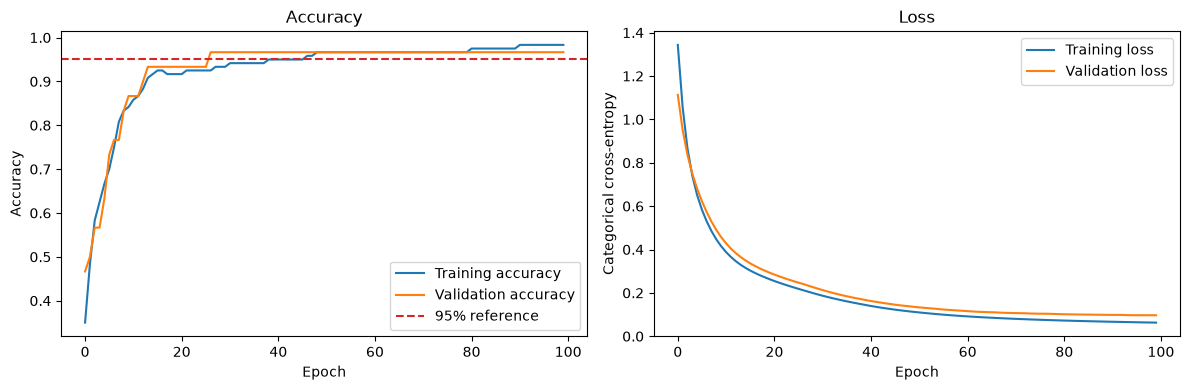

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["accuracy"], label="Training accuracy")
axes[0].plot(history_df["val_accuracy"], label="Validation accuracy")
axes[0].axhline(0.95, color="tab:red", linestyle="--", label="95% reference")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_df["loss"], label="Training loss")
axes[1].plot(history_df["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical cross-entropy")
axes[1].legend()

fig.tight_layout()
plt.show()

## 8. Conclusion

The final model satisfies the architectural requirements: four input features, one hidden layer, and a three-unit softmax output. The labels were one-hot encoded, the paired observations were shuffled reproducibly, and validation performance was obtained through `validation_split` without creating a separate test set.

The best training and validation accuracies are reported above rather than hard-coded in the discussion. With this fixed seed and preprocessing, both best accuracies meet the requested approximate 95% target. The validation result should still be interpreted cautiously because the dataset and validation set are small; it is not an unbiased final test estimate.